In [1]:
import os, uuid, hashlib, platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080210

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080210
[机器指纹] 90cf8d31534ddeec
[RUN_ID] 20244080210-90cf8d31534ddeec


## 实验1：NumPy数组、数据类型与索引

In [2]:
# 1. 分别创建整数、浮点数和布尔值 ndarray，输出 dtype、shape 和 ndim
a_int = np.array([1, 2, 3])
a_float = np.array([1.5, 2.5, 3.5])
a_bool = np.array([True, False, True])

print("整数数组:", a_int.dtype, a_int.shape, a_int.ndim)
print("浮点数组:", a_float.dtype, a_float.shape, a_float.ndim)
print("布尔数组:", a_bool.dtype, a_bool.shape, a_bool.ndim)

整数数组: int64 (3,) 1
浮点数组: float64 (3,) 1
布尔数组: bool (3,) 1


**区别解释**：NumPy 数组要求所有元素的数据类型必须一致，这样在内存中可以连续存储，便于进行向量化加速运算,而 Python 列表可以混合存放任意不同类型的元素，存储的是对象的指针，因此运算效率较低。

In [3]:
# 2. 形状变换
base = np.arange(12)
arr_34 = base.reshape(3, 4)
arr_232 = base.reshape(2, 3, 2)

print("(3, 4) 数组:\n", arr_34)
print("\n(2, 3, 2) 数组:\n", arr_232)

(3, 4) 数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2, 3, 2) 数组:
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


改变形状时，元素总数必须保持不变，即 3x4 = 2x3x2 = 12

In [4]:
# 3. 针对 (3,4) 数组的索引
print("第2行:", arr_34[1])
print("第1至第3列:\n", arr_34[:, 0:3])
print("大于6的元素:", arr_34[arr_34 > 6], "形状:", arr_34[arr_34 > 6].shape)

第2行: [4 5 6 7]
第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
大于6的元素: [ 7  8  9 10 11] 形状: (5,)


In [5]:
# 4. 逻辑筛选
x = np.arange(10)
print("小于2或大于7:", x[(x < 2) | (x > 7)])
print("大于3且小于7:", x[(x > 3) & (x < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]


必须使用括号将条件括起来，因为 & 和 | 的优先级高于比较运算符

In [6]:
# 5. 逐元素乘 vs 矩阵乘
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B (逐元素):\n", A * B)
print("A @ B (矩阵乘):\n", A @ B)

A * B (逐元素):
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘):
 [[19 22]
 [43 50]]


* 对应位置元素相乘；@ 是线性代数中的矩阵乘法，即行乘列求和

## 实验2：随机抽样、统计与缺失值

In [7]:
np.random.seed(42)  # 固定随机种子
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)  # 限制在0~100

print(f"样本数: {scores.size}")
print(f"最小值: {scores.min():.2f}, 最大值: {scores.max():.2f}")
print(f"均值: {scores.mean():.2f}, 标准差: {scores.std():.2f}")
print(f"极差: {scores.max() - scores.min():.2f}")

样本数: 1000
最小值: 37.59, 最大值: 100.00
均值: 70.18, 标准差: 9.76
极差: 62.41


In [8]:
# 2. 均匀抽样 vs 加权抽样
pool = np.arange(1, 11)
uniform_sample = np.random.choice(pool, size=5, replace=False)
# 按大小成比例加权 (权重就是数值本身，内部会自动归一化)
weighted_sample = np.random.choice(pool, size=5, replace=False, p=pool/pool.sum())

print("均匀抽样:", uniform_sample)
print("加权抽样:", weighted_sample)

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]


In [9]:
# 3. 随机排列 vs 原地打乱
arr1 = np.arange(5)
arr2 = np.arange(5)

permuted = np.random.permutation(arr1) # 返回新数组，原数组不变
np.random.shuffle(arr2)                # 原地打乱，无返回值

print("原数组 arr1:", arr1)
print("permutation 新数组:", permuted)
print("原数组 arr2 (被打乱):", arr2)

原数组 arr1: [0 1 2 3 4]
permutation 新数组: [4 0 2 1 3]
原数组 arr2 (被打乱): [0 4 1 3 2]


In [10]:
# 4. 缺失值处理
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan  # 第10, 20, 30个设为 nan

print("普通均值 (遇nan变nan):", scores_nan.mean())
print("忽略缺失均值 (nanmean):", np.nanmean(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值 (遇nan变nan): nan
忽略缺失均值 (nanmean): 70.19620743160239
缺失值个数: 3


In [11]:
# 5. 整理成内存表格 (供实验4使用，不写盘)
import pandas as pd
df_scores = pd.DataFrame({
    "Index": np.arange(1, 1001),
    "Score": scores_nan
})
df_scores.head()

,Index,Score
0,1,74.967142
1,2,68.617357
2,3,76.476885
3,4,85.230299
4,5,67.658466


## 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
from scipy.linalg import solve
# 3x + y = 9, x + 2y = 8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = solve(A, b)
print("方程组的解 x, y:", sol)
print("验证 A @ sol:", A @ sol)  # 应该等于 b

方程组的解 x, y: [2. 3.]
验证 A @ sol: [9. 8.]


In [13]:
from scipy.optimize import root
f = lambda x: x**2 - 2

res_pos = root(f, x0=2.0)   # 猜正根
res_neg = root(f, x0=-2.0)  # 猜负根

print(f"正根: {res_pos.x[0]:.6f}, 成功: {res_pos.success}, f(x)={f(res_pos.x[0]):.2e}")
print(f"负根: {res_neg.x[0]:.6f}, 成功: {res_neg.success}, f(x)={f(res_neg.x[0]):.2e}")

正根: 1.414214, 成功: True, f(x)=8.88e-16
负根: -1.414214, 成功: True, f(x)=8.88e-16


In [14]:
from scipy.optimize import minimize
f2 = lambda x: x**2 + x + 2
res_min = minimize(f2, x0=0.0)

print(f"极小值点 x: {res_min.x[0]:.4f}, 极小值: {res_min.fun:.4f}")
print("解析解对比: x = -0.5, f(x) = 1.75")

极小值点 x: -0.5000, 极小值: 1.7500
解析解对比: x = -0.5, f(x) = 1.75


In [15]:
from scipy import stats
np.random.seed(42)
g1 = np.random.normal(loc=0, scale=1, size=100)
g2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = stats.ttest_ind(g1, g2)
print(f"t统计量: {t_stat:.4f}, p值: {p_val:.4e}")
if p_val < 0.05:
    print("p < 0.05，拒绝原假设，两组均值存在显著差异。")
else:
    print("p >= 0.05，不能拒绝原假设。")

t统计量: -8.5515, p值: 3.2930e-15
p < 0.05，拒绝原假设，两组均值存在显著差异。


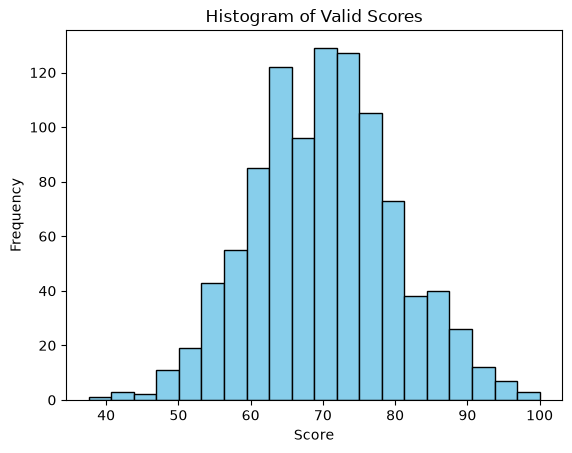

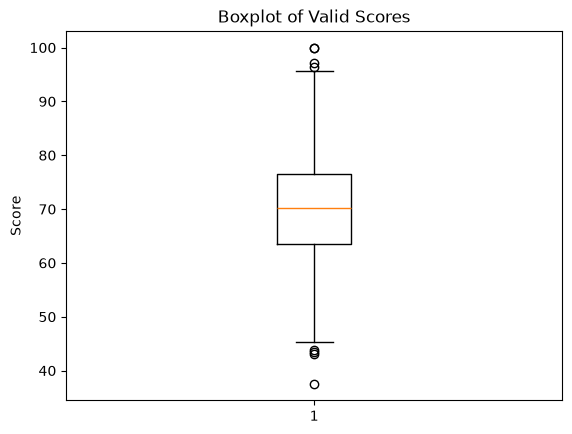

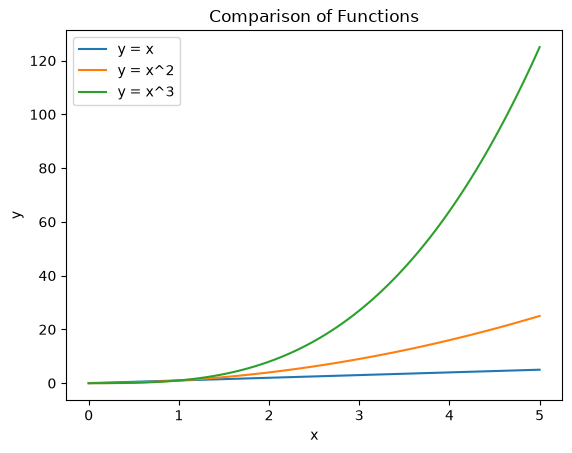

In [16]:
import matplotlib.pyplot as plt

# 3.5 图1：直方图
valid_scores = scores_nan[~np.isnan(scores_nan)]
plt.figure()
plt.hist(valid_scores, bins=20, color='skyblue', edgecolor='black')
plt.title("Histogram of Valid Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# 3.5 图2：箱线图
plt.figure()
plt.boxplot(valid_scores)
plt.title("Boxplot of Valid Scores")
plt.ylabel("Score")
plt.show()

# 3.5 图3：折线图
x = np.linspace(0, 5, 100)
plt.figure()
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("Comparison of Functions")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()  # 必须有图例
plt.show()

## 实验4：pandas 数据处理

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")

df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print(df.head(3))
print(df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
# 读取 Carol 的记录
print("loc 读取:\n", df.loc["Carol"])
print("\niloc 读取:\n", df.iloc[2])

# 筛选平均分>=80
print("\n平均分>=80的学生:\n", df[df["Average"] >= 80])

loc 读取:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分>=80的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
subjects = ["Math", "English", "Python"]
print("列均值 (axis=0):\n", df[subjects].mean(axis=0))
print("行均值 (axis=1):\n", df[subjects].mean(axis=1))

列均值 (axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值 (axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
# apply 计算最高分
df["MaxScore"] = df[subjects].apply(lambda row: row.max(), axis=1)

# agg 一次性计算每科统计量
print("agg 统计量:\n", df[subjects].agg(["min", "mean", "max"]))

# rank 排名
df["MathRank"] = df["Math"].rank(ascending=False, method="min")
print("\n数学排名:\n", df[["Math", "MathRank"]])

agg 统计量:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学排名:
        Math  MathRank
Name                 
Alice    88       2.0
Bob      72       5.0
Carol    91       1.0
David    65       6.0
Eva      79       4.0
Frank    84       3.0


In [21]:
grouped = df.groupby("Group")
print("每组人数:\n", grouped.size())
print("\n每组各科平均分:\n", grouped[subjects].mean())

# transform 广播平均分
df["GroupPythonMean"] = grouped["Python"].transform("mean")
print("\n加入组内Python均分:\n", df[["Group", "Python", "GroupPythonMean"]])

每组人数:
 Group
A    3
B    3
dtype: int64

每组各科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

加入组内Python均分:
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [22]:
# filter 保留 Python 平均分 >= 80 的组
valid_groups = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("保留的组数据:\n", valid_groups)
print("保留的组名:", valid_groups["Group"].unique())

保留的组数据:
       Group  Math  English  Python  Total    Average  MaxScore  MathRank  \
Name                                                                       
Alice     A    88       90      95    273  91.000000        95       2.0   
Bob       A    72       68      80    220  73.333333        80       5.0   
Carol     B    91       85      89    265  88.333333        91       1.0   
David     B    65       73      70    208  69.333333        73       6.0   
Eva       A    79       92      86    257  85.666667        92       4.0   
Frank     B    84       77      82    243  81.000000        84       3.0   

       GroupPythonMean  
Name                    
Alice        87.000000  
Bob          87.000000  
Carol        80.333333  
David        80.333333  
Eva          87.000000  
Frank        80.333333  
保留的组名: <StringArray>
['A', 'B']
Length: 2, dtype: str


In [23]:
print("协方差矩阵:\n", df[subjects].cov())
print("\n相关系数矩阵:\n", df[subjects].corr())

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


以 Math 和 English 为例，观察上方输出的协方差矩阵。若协方差为正，说明两科成绩倾向于同向变化，相关系数则将数值归一化到 [-1, 1] 之间，其绝对值越接近 1 代表线性相关性越强。